# Notebook 05 – Final Model Evaluation

In Notebook 03, Linear Regression was selected as the preferred classical machine learning model based on its cross validation performance.
I will now train the selected Linear Regression model using the full training dataset and evaluate its performance on the unseen test dataset.

The test dataset has not been used during model training or selection.

## Setup

In [1]:
import sys
sys.path.append("../src")
from read_data import load_data
from preprocess import prepare_data, build_preprocessor
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score,  root_mean_squared_error
import matplotlib.pyplot as plt
import pandas as pd
from evaluation import create_bands
from sklearn.inspection import permutation_importance

## Load and preprocess the data

Use the same training and test split as the previous notebooks

In [2]:
df = load_data()
X, y = prepare_data(df)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape)
print("Test rows:", X_test.shape)

Training rows: (429, 7)
Test rows: (108, 7)


## Build Model

In [3]:
final_model = make_pipeline(build_preprocessor(),LinearRegression())

# Train the final Linear Regression model using the full training dataset
final_model.fit(X_train, y_train)
print("Final Linear Regression model trained.")

Final Linear Regression model trained.


## Predict the test set.
The test set was held back and not used during training or model selection, allowing the final model to be evaluated on unseen data.

In [4]:
# Use the trained model to predict FPL points for the test data
y_pred = final_model.predict(X_test)

# Calculate the final test performance metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Final Test Results")
test_results = pd.DataFrame({
    "MAE": [mae],
    "RMSE": [rmse],
    "R2": [r2]
}, index=["Results"])

display(test_results.round(2))

Final Test Results


,MAE,RMSE,R2
Results,10.6,14.27,0.92


## Prediction errors

Analyse predictions to identify the predictions errors made by the final model.

In [5]:
# Display actual and predicted points
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
},index=y_test.index)


# Calculate signed and absolute prediction errors
results["Error"] = results["Predicted"] - results["Actual"]
results["Absolute Error"] = results["Error"].abs()

print("5 Worst Predictions")
display(results.sort_values("Absolute Error", ascending=False).head(5).round(2))

5 Worst Predictions


,Actual,Predicted,Error,Absolute Error
121,96,143.30,47.30,47.30
88,70,116.44,46.44,46.44
558,165,119.49,-45.51,45.51
544,95,58.32,-36.68,36.68
0,162,197.38,35.38,35.38


The five worst predictions had errors ranging from 35 to 47 points. The model overestimated and underestimated player performance so there is no clear pattern in the worst predictions.

## Residual Plot

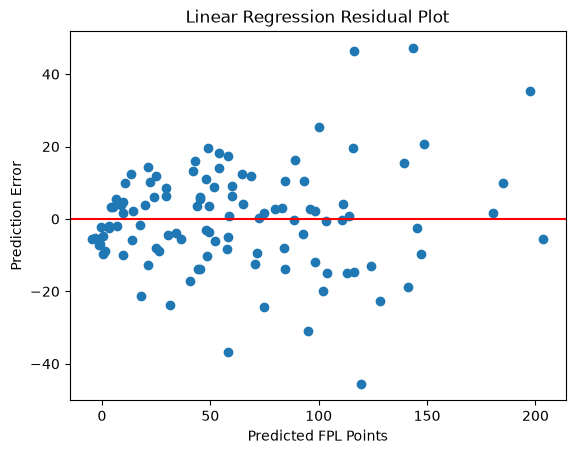

In [6]:
plt.scatter(results["Predicted"], results["Error"])

plt.axhline(y=0, color="red")
plt.xlabel("Predicted FPL Points")
plt.ylabel("Prediction Error")
plt.title("Linear Regression Residual Plot")
plt.show()

### Residual Plot Analysis

The residual plot shows the difference between actual and predicted FPL points for the 108 test players.

The errors are generally smaller for players with lower predicted points and larger as the points increase.

The model both overpredicts and underpredicts FPL points, with some errors exceeding 40 points.
Although the Linear Regression model performs well its predictions may be less reliable for players with higher FPL points.

## Error analysis by point bands

Group players into low, medium and high fpl points and show the average error for each band.

In [7]:
# Group players according to their FPL points
bands = create_bands(results["Actual"])


band_results = pd.DataFrame({
    "Players per band": results.groupby(bands).size(),
    "Mean Error": results.groupby(bands)["Error"].mean(),
    "MAE": results.groupby(bands)["Absolute Error"].mean(),
    "SD": results.groupby(bands)["Absolute Error"].std()
})
band_results.index.name = "Points"
display(band_results.round(2))

,Players per band,Mean Error,MAE,SD
Points,,,,
Low (0-30),33,2.49,6.99,4.57
Medium (30-80),40,1.72,10.20,8.62
High (80+),35,-4.70,14.45,12.51


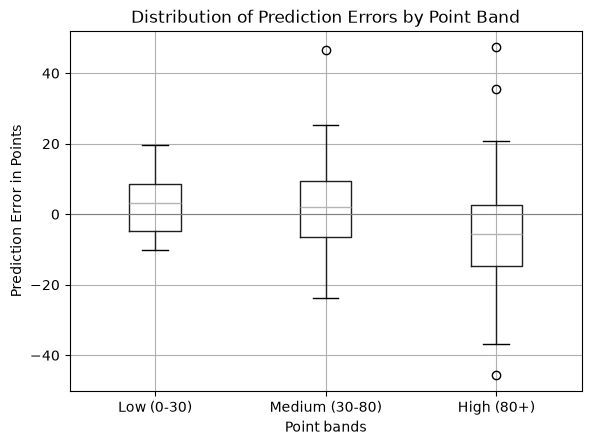

In [8]:
results["Band"] = bands
results.boxplot(column="Error", by="Band")
plt.axhline(0, color="grey", linewidth=0.8)
plt.ylabel("Prediction Error in Points")
plt.xlabel("Point bands")
plt.title("Distribution of Prediction Errors by Point Band")
plt.suptitle("")
plt.grid(True)
plt.show()

Both MAE and SD increase as we move from the low points band to the high points band. This shows that the model is less accurate when predicting points for players with high points and the prediction errors varies more between these players. The graph also shows that the model tends to underpredict players with high points.

## Model Interpretation with Feature Coefficients
Examine which features contribute most to the predicted points

In [9]:
# Calculate permutation importance for the original features
permutation = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42
)

# Create a table of permutation importance results
perm_results = pd.DataFrame({
    "Feature": X_test.columns,
    "Avg MAE increase": permutation.importances_mean,
    "Std": permutation.importances_std
})

# Sort features by importance
perm_results = perm_results.sort_values(
    "Avg MAE increase", ascending=False
)

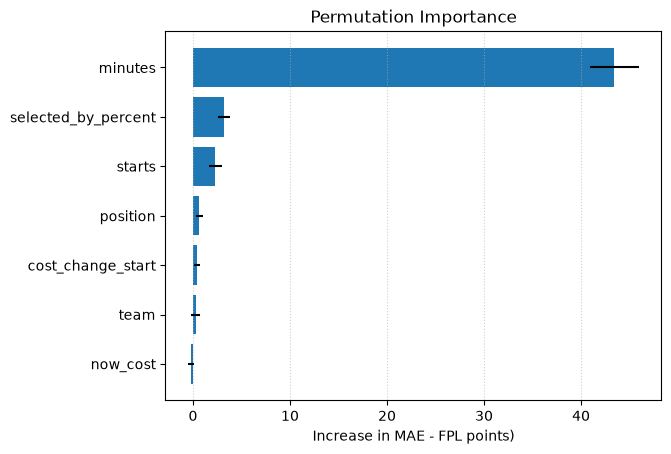

In [10]:
#plt.figure(figsize=(9, 5))
plt.barh(
    perm_results['Feature'],
    perm_results['Avg MAE increase'],
    xerr=perm_results['Std']
)
plt.gca().invert_yaxis()
plt.xlabel("Increase in MAE - FPL points)")
plt.title("Permutation Importance")
plt.grid(linestyle=':', alpha=0.6, axis='x')
#plt.tight_layout()
plt.show()

Minutes played was by far the most important feature in predicting FPL points. Shuffling this feature increased the MAE by approximately 43 points. Player selection percentage and starts were the next most important features. The remaining features had lower importance scores.

## Conclusion

The final Linear Regression model achieved an MAE of 10.60, an RMSE of 14.27 and an R² of 0.92 on the test data. The error analysis showed that the model was less accurate when predicting points for players with high points and tended to underpredict their points. 

Permutation importance identified minutes played as by far the most important feature, followed by player selection percentage and starts. 

Overall, the model performed well in estimating FPL points for the 2025-2026 season.